<a href="https://colab.research.google.com/github/ayeshaalamexe/ds311-phishguard/blob/main/notebooks/03_mining_lead.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install ucimlrepo -q

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

pd.set_option("display.max_rows", 100)
SEED = 42

In [3]:
from ucimlrepo import fetch_ucirepo

d = fetch_ucirepo(id=967)
X = d.data.features
y = d.data.targets
df = pd.concat([X, y], axis=1)

LABEL = "label"
print(df.shape)
print(df[LABEL].value_counts())
df.head()

(235795, 55)
label
1    134850
0    100945
Name: count, dtype: int64


,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,0.061933,...,0,0,1,34,20,28,119,0,124,1
1,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,0.050207,...,0,0,1,50,9,8,39,0,217,1
2,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,0.064129,...,0,0,1,10,2,7,42,2,5,1
3,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,0.057606,...,1,1,1,3,27,15,22,1,31,1
4,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,0.059441,...,1,0,1,244,15,34,72,1,85,1


In [4]:
info = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "missing": df.isna().sum(),
    "example": df.iloc[0].astype(str)
})
info

,dtype,n_unique,missing,example
URL,object,235370,0,https://www.southbankmosaics.com
URLLength,int64,482,0,31
Domain,object,220086,0,www.southbankmosaics.com
DomainLength,int64,101,0,24
IsDomainIP,int64,2,0,0
TLD,object,695,0,com
URLSimilarityIndex,float64,36360,0,100.0
CharContinuationRate,float64,898,0,1.0
TLDLegitimateProb,float64,465,0,0.5229071
URLCharProb,float64,227421,0,0.061933179


In [5]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate URLs:", df["URL"].duplicated().sum())

dup = df[df["URL"].duplicated(keep=False)]
print("Rows with a repeated URL:", len(dup))

labels_per_url = dup.groupby("URL")[LABEL].nunique()
print("URLs with conflicting labels:", (labels_per_url > 1).sum())
print(dup[LABEL].value_counts())

Missing values: 0
Duplicate rows: 0
Duplicate URLs: 425
Rows with a repeated URL: 850
URLs with conflicting labels: 0
label
0    850
Name: count, dtype: int64


In [6]:
before = len(df)
df_clean = df.drop_duplicates(subset="URL", keep="first").reset_index(drop=True)
print(before, "->", len(df_clean), "rows. Removed:", before - len(df_clean))
print(df_clean[LABEL].value_counts())

df_clean["is_phish"] = (df_clean[LABEL] == 0).astype(int)

235795 -> 235370 rows. Removed: 425
label
1    134850
0    100520
Name: count, dtype: int64


In [7]:
text_cols = df_clean.select_dtypes(include="object").columns.tolist()
print("Text columns:", text_cols)

num_cols = []
for c in df_clean.select_dtypes("number").columns:
    if c != LABEL and c != "is_phish":
        num_cols.append(c)
print("Number of numeric features:", len(num_cols))

const = [c for c in num_cols if df_clean[c].nunique() <= 1]
print("Constant columns:", const)

Text columns: ['URL', 'Domain', 'TLD', 'Title']
Number of numeric features: 50
Constant columns: []


label
1    0.573
0    0.427
Name: proportion, dtype: float64


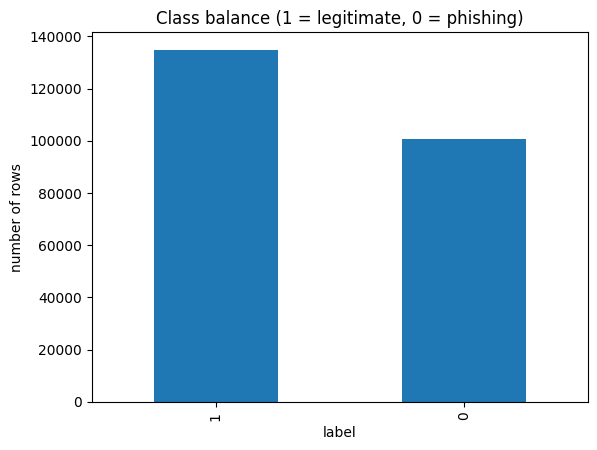

In [8]:
counts = df_clean[LABEL].value_counts()
print(df_clean[LABEL].value_counts(normalize=True).round(3))

counts.plot(kind="bar", title="Class balance (1 = legitimate, 0 = phishing)")
plt.ylabel("number of rows")
plt.show()

In [9]:
group_a = ["URLLength", "DomainLength", "IsDomainIP", "TLDLength", "NoOfSubDomain",
           "CharContinuationRate", "HasObfuscation", "NoOfObfuscatedChar", "ObfuscationRatio",
           "NoOfLettersInURL", "LetterRatioInURL", "NoOfDegitsInURL", "DegitRatioInURL",
           "NoOfEqualsInURL", "NoOfQMarkInURL", "NoOfAmpersandInURL",
           "NoOfOtherSpecialCharsInURL", "SpacialCharRatioInURL", "IsHTTPS"]
group_a = [c for c in group_a if c in df_clean.columns]

group_b = ["URLSimilarityIndex", "TLDLegitimateProb", "URLCharProb"]

dd = info.copy()
dd["url_computable"] = "no (needs webpage)"
for c in group_a + ["URL", "Domain", "TLD"]:
    dd.loc[c, "url_computable"] = "yes"
for c in group_b:
    dd.loc[c, "url_computable"] = "check"

dd["use"] = "keep"
for c in ["URL", "Domain", "TLD", "Title"]:
    dd.loc[c, "use"] = "text-only"
dd.loc["URLSimilarityIndex", "use"] = "leakage suspect"
dd.loc[LABEL, "use"] = "target"

dd["meaning"] = ""
dd.to_csv("data_dictionary.csv")
dd

,dtype,n_unique,missing,example,url_computable,use,meaning
URL,object,235370,0,https://www.southbankmosaics.com,yes,text-only,
URLLength,int64,482,0,31,yes,keep,
Domain,object,220086,0,www.southbankmosaics.com,yes,text-only,
DomainLength,int64,101,0,24,yes,keep,
IsDomainIP,int64,2,0,0,yes,keep,
TLD,object,695,0,com,yes,text-only,
URLSimilarityIndex,float64,36360,0,100.0,check,leakage suspect,
CharContinuationRate,float64,898,0,1.0,yes,keep,
TLDLegitimateProb,float64,465,0,0.5229071,check,keep,
URLCharProb,float64,227421,0,0.061933179,check,keep,


label                            0       1
URLLength                   45.703  26.229
DomainLength                24.444  19.229
IsDomainIP                   0.006   0.000
TLDLength                    2.819   2.723
NoOfSubDomain                1.169   1.162
CharContinuationRate         0.729   0.933
HasObfuscation               0.005   0.000
NoOfObfuscatedChar           0.058   0.000
ObfuscationRatio             0.000   0.000
NoOfLettersInURL            28.089  12.933
LetterRatioInURL             0.568   0.477
NoOfDegitsInURL              4.324   0.051
DegitRatioInURL              0.064   0.002
NoOfEqualsInURL              0.146   0.000
NoOfQMarkInURL               0.069   0.000
NoOfAmpersandInURL           0.059   0.000
NoOfOtherSpecialCharsInURL   3.800   1.245
SpacialCharRatioInURL        0.083   0.048
IsHTTPS                      0.491   1.000


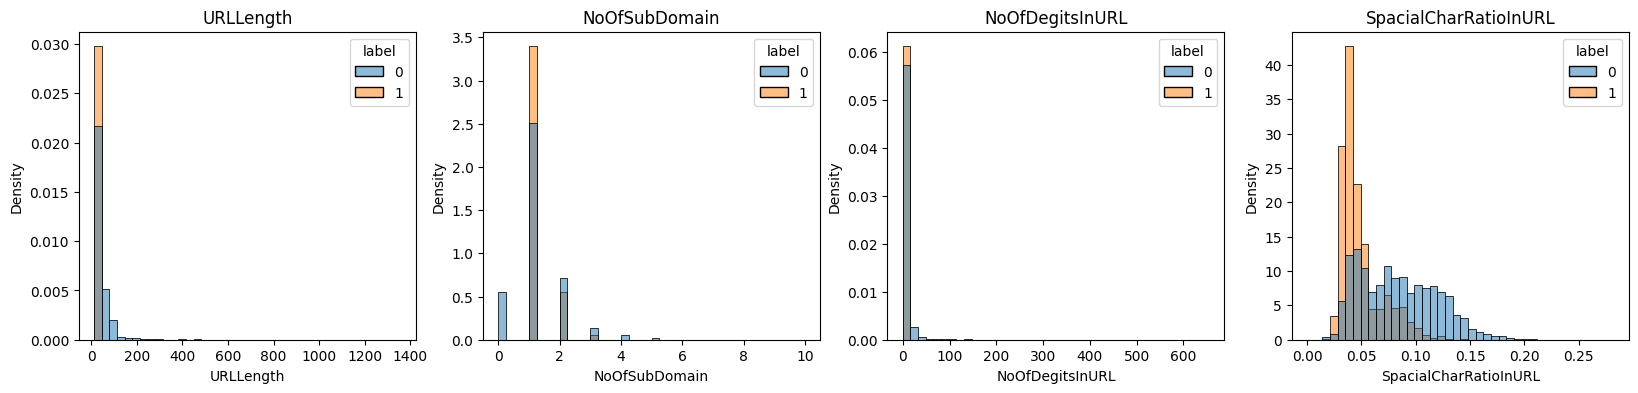

In [10]:
print(df_clean.groupby(LABEL)[group_a].mean().T.round(3))

small = df_clean.sample(50000, random_state=SEED)
cols = ["URLLength", "NoOfSubDomain", "NoOfDegitsInURL", "SpacialCharRatioInURL"]
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for i in range(4):
    sns.histplot(data=small, x=cols[i], hue=LABEL, bins=40,
                 stat="density", common_norm=False, ax=axes[i])
    axes[i].set_title(cols[i])
plt.show()

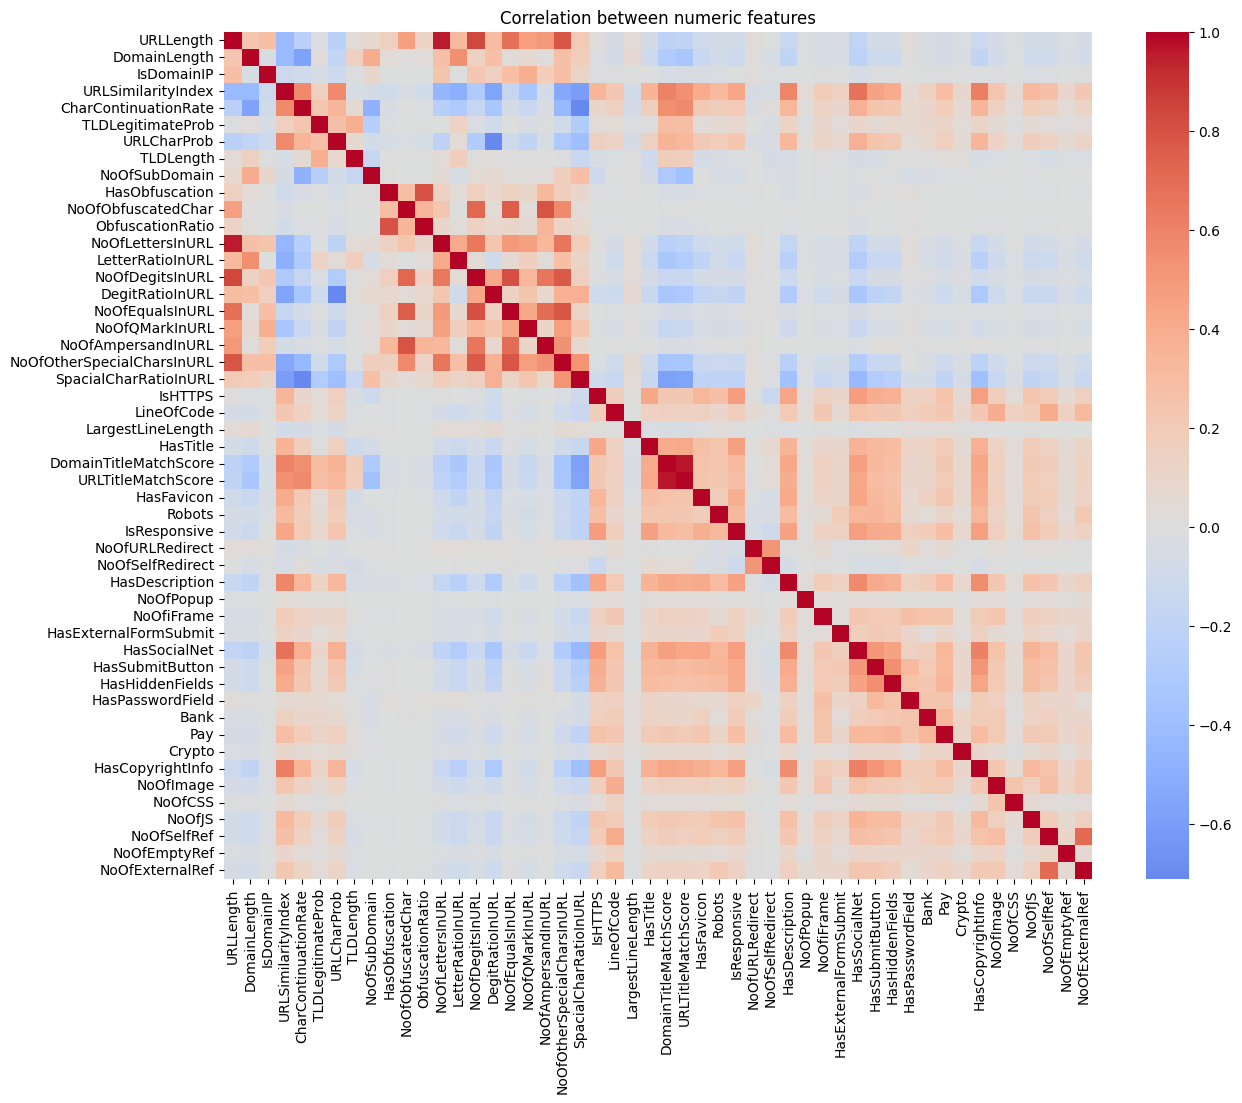

Highly correlated pairs: 2
('URLLength', 'NoOfLettersInURL', np.float64(0.956))
('DomainTitleMatchScore', 'URLTitleMatchScore', np.float64(0.961))


In [11]:
corr = df_clean[num_cols].corr()

plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Correlation between numeric features")
plt.show()

high_pairs = []
for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        if abs(corr.iloc[i, j]) > 0.9:
            high_pairs.append((corr.columns[i], corr.columns[j], round(corr.iloc[i, j], 3)))
print("Highly correlated pairs:", len(high_pairs))
for p in high_pairs:
    print(p)

In [12]:
phish_len = df_clean[df_clean[LABEL] == 0]["URLLength"]
legit_len = df_clean[df_clean[LABEL] == 1]["URLLength"]

u, p = stats.mannwhitneyu(phish_len, legit_len, alternative="two-sided")
effect = u / (len(phish_len) * len(legit_len))

print("Median length, phishing:", phish_len.median())
print("Median length, legitimate:", legit_len.median())
print("p-value:", p)
print("Effect size:", round(effect, 3))

Median length, phishing: 34.0
Median length, legitimate: 26.0
p-value: 0.0
Effect size: 0.732


In [13]:
scan, _ = train_test_split(df_clean, train_size=50000,
                           stratify=df_clean[LABEL], random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

scores = {}
for c in num_cols:
    tree = DecisionTreeClassifier(max_depth=3, random_state=SEED)
    scores[c] = cross_val_score(tree, scan[[c]], scan[LABEL], cv=cv, scoring="roc_auc").mean()

leak = pd.Series(scores).sort_values(ascending=False)
print(leak.head(15).round(4))

suspects = leak[leak > 0.95].index.tolist()
print("Suspects:", suspects)

URLSimilarityIndex            0.9955
LineOfCode                    0.9894
NoOfExternalRef               0.9848
NoOfImage                     0.9815
NoOfJS                        0.9735
NoOfSelfRef                   0.9711
NoOfCSS                       0.9555
HasSocialNet                  0.8950
HasCopyrightInfo              0.8760
LargestLineLength             0.8532
HasDescription                0.8466
NoOfOtherSpecialCharsInURL    0.8207
SpacialCharRatioInURL         0.7998
DomainTitleMatchScore         0.7994
HasSubmitButton               0.7889
dtype: float64
Suspects: ['URLSimilarityIndex', 'LineOfCode', 'NoOfExternalRef', 'NoOfImage', 'NoOfJS', 'NoOfSelfRef', 'NoOfCSS']


In [14]:
def cv_auc(cols):
    tree = DecisionTreeClassifier(max_depth=5, random_state=SEED)
    return cross_val_score(tree, df_clean[cols], df_clean[LABEL], cv=cv, scoring="roc_auc").mean()

no_url_sim = [c for c in num_cols if c != "URLSimilarityIndex"]
no_suspect = [c for c in num_cols if c not in suspects]

print("All numeric features:       ", round(cv_auc(num_cols), 4))
print("Without URLSimilarityIndex: ", round(cv_auc(no_url_sim), 4))
print("Without all suspects:       ", round(cv_auc(no_suspect), 4))
print("URL-only features:          ", round(cv_auc(group_a), 4))

All numeric features:        1.0
Without URLSimilarityIndex:  0.9973
Without all suspects:        0.9954
URL-only features:           0.9907


In [15]:
url_no_https = [c for c in group_a if c != "IsHTTPS"]
print("With IsHTTPS:   ", round(cv_auc(group_a), 4))
print("Without IsHTTPS:", round(cv_auc(url_no_https), 4))

With IsHTTPS:    0.9907
Without IsHTTPS: 0.8556


In [16]:
train, test = train_test_split(df_clean, test_size=0.2,
                               stratify=df_clean[LABEL], random_state=SEED)
print("Train:", train.shape, "Test:", test.shape)

def evaluate(model, cols, name):
    model.fit(train[cols], train["is_phish"])
    pred = model.predict(test[cols])
    prob = model.predict_proba(test[cols])[:, 1]
    print(name, "-", len(cols), "features")
    print(classification_report(test["is_phish"], pred,
                                target_names=["legitimate", "phishing"], digits=4))
    print("Confusion matrix (rows = true, columns = predicted):")
    print(confusion_matrix(test["is_phish"], pred))
    print("ROC-AUC:", round(roc_auc_score(test["is_phish"], prob), 4))
    print()

evaluate(DecisionTreeClassifier(max_depth=5, random_state=SEED), num_cols, "Decision tree, all features")
evaluate(DecisionTreeClassifier(max_depth=5, random_state=SEED), no_suspect, "Decision tree, no suspects")
evaluate(DecisionTreeClassifier(max_depth=5, random_state=SEED), group_a, "Decision tree, URL-only")
evaluate(GaussianNB(), no_suspect, "Naive Bayes, no suspects")
evaluate(GaussianNB(), group_a, "Naive Bayes, URL-only")

Train: (188296, 56) Test: (47074, 56)
Decision tree, all features - 50 features
              precision    recall  f1-score   support

  legitimate     1.0000    1.0000    1.0000     26970
    phishing     1.0000    1.0000    1.0000     20104

    accuracy                         1.0000     47074
   macro avg     1.0000    1.0000    1.0000     47074
weighted avg     1.0000    1.0000    1.0000     47074

Confusion matrix (rows = true, columns = predicted):
[[26970     0]
 [    0 20104]]
ROC-AUC: 1.0

Decision tree, no suspects - 43 features
              precision    recall  f1-score   support

  legitimate     0.9862    0.9894    0.9878     26970
    phishing     0.9858    0.9814    0.9836     20104

    accuracy                         0.9860     47074
   macro avg     0.9860    0.9854    0.9857     47074
weighted avg     0.9860    0.9860    0.9860     47074

Confusion matrix (rows = true, columns = predicted):
[[26685   285]
 [  373 19731]]
ROC-AUC: 0.9952

Decision tree, URL-only - 

In [17]:
df_clean.to_csv("clean_data.csv", index=False)
leak.to_csv("leakage_scan.csv")

sample_small, _ = train_test_split(df_clean, train_size=5000,
                                   stratify=df_clean[LABEL], random_state=SEED)
sample_small.to_csv("sample_5000.csv", index=False)
print("Saved all files.")

Saved all files.


Minning lead (Sara): feature selection, models, leakage check, clustring

In [18]:
# TASK: Mining Lead - Step 1: imports, result folder, and data samples
import os
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.feature_selection import mutual_info_classif, chi2
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.model_selection import cross_validate, GroupKFold

os.makedirs("results", exist_ok=True)

TARGET = "is_phish"   # 1 = phishing, 0 = legitimate
FEATS = no_suspect    # the 43 features without leakage suspects

# sample 1: used ONLY to rank features
fs_data, rest = train_test_split(df_clean, train_size=50000,
                                 stratify=df_clean[TARGET], random_state=SEED)
# sample 2: used ONLY to evaluate models (different rows from sample 1)
ev_data, _ = train_test_split(rest, train_size=50000,
                              stratify=rest[TARGET], random_state=SEED)

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print("Feature-ranking sample:", fs_data.shape, "| Evaluation sample:", ev_data.shape)
print("Features used:", len(FEATS))

Feature-ranking sample: (50000, 56) | Evaluation sample: (50000, 56)
Features used: 43


In [19]:
# TASK: Mining Lead - Step 2: rank features with 3 methods
X_fs = fs_data[FEATS]
y_fs = fs_data[TARGET]

# 1) Mutual information: how much a feature tells us about the label
mi_scores = mutual_info_classif(X_fs, y_fs, random_state=SEED)

# 2) Chi-square: needs values >= 0, so scale to 0-1 first
chi_scores, _ = chi2(MinMaxScaler().fit_transform(X_fs), y_fs)

# 3) Random forest importance
rf_sel = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)
rf_sel.fit(X_fs, y_fs)

ranking = pd.DataFrame({"feature": FEATS,
                        "mutual_info": mi_scores,
                        "chi2": chi_scores,
                        "rf_importance": rf_sel.feature_importances_})
methods = ["mutual_info", "chi2", "rf_importance"]
for m in methods:
    ranking[m + "_rank"] = ranking[m].rank(ascending=False)
ranking["avg_rank"] = ranking[[m + "_rank" for m in methods]].mean(axis=1)
ranking = ranking.sort_values("avg_rank").reset_index(drop=True)

ranking.to_csv("results/feature_ranking.csv", index=False)
ranking.head(15)

,feature,mutual_info,chi2,rf_importance,mutual_info_rank,chi2_rank,rf_importance_rank,avg_rank
0,HasSocialNet,0.387556,16590.922271,0.150610,2.0,1.0,1.0,1.333333
1,HasCopyrightInfo,0.329605,14228.620325,0.147536,4.0,2.0,2.0,2.666667
2,HasDescription,0.288336,13430.307196,0.069185,5.0,3.0,5.0,4.333333
3,DomainTitleMatchScore,0.196174,8420.441095,0.053833,9.0,5.0,7.0,7.000000
4,IsHTTPS,0.233760,4068.586502,0.092737,7.0,12.0,3.0,7.333333
5,HasSubmitButton,0.195097,9935.410410,0.036114,10.0,4.0,8.0,7.333333
6,URLTitleMatchScore,0.173176,6901.342862,0.028286,12.0,8.0,10.0,10.000000
7,IsResponsive,0.163703,5723.859315,0.023440,17.0,9.0,12.0,12.666667
8,DegitRatioInURL,0.166892,2398.013904,0.024245,16.0,13.0,11.0,13.333333
9,NoOfOtherSpecialCharsInURL,0.239718,82.392912,0.060215,6.0,31.0,6.0,14.333333


done: All 43 k = 1
done: All 43 k = 2
done: All 43 k = 3
done: All 43 k = 5
done: All 43 k = 8
done: All 43 k = 10
done: All 43 k = 15
done: All 43 k = 20
done: All 43 k = 30
done: All 43 k = 43
done: URL-only 19 k = 1
done: URL-only 19 k = 2
done: URL-only 19 k = 3
done: URL-only 19 k = 5
done: URL-only 19 k = 8
done: URL-only 19 k = 10
done: URL-only 19 k = 15
done: URL-only 19 k = 19
   feature_pool   k  roc_auc  phish_recall
0        All 43   1   0.8932        0.9949
1        All 43   2   0.9673        0.9393
2        All 43   3   0.9831        0.9063
3        All 43   5   0.9968        0.9749
4        All 43   8   0.9979        0.9822
5        All 43  10   0.9990        0.9870
6        All 43  15   0.9999        0.9959
7        All 43  20   0.9999        0.9964
8        All 43  30   1.0000        0.9975
9        All 43  43   1.0000        0.9985
10  URL-only 19   1   0.7544        0.5089
11  URL-only 19   2   0.9160        0.8373
12  URL-only 19   3   0.9880        0.9542
13  URL-

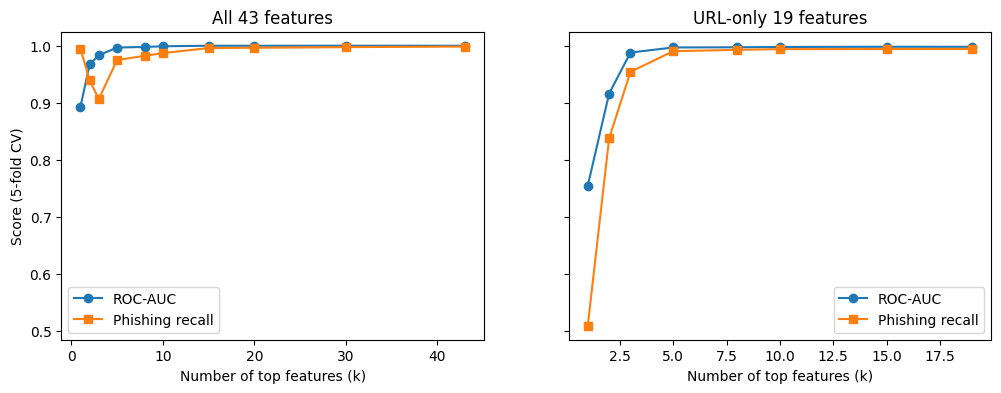


Chosen k (all 43): 10 -> ['HasSocialNet', 'HasCopyrightInfo', 'HasDescription', 'DomainTitleMatchScore', 'IsHTTPS', 'HasSubmitButton', 'URLTitleMatchScore', 'IsResponsive', 'DegitRatioInURL', 'NoOfOtherSpecialCharsInURL']
Chosen k (URL-only): 8 -> ['IsHTTPS', 'DegitRatioInURL', 'NoOfOtherSpecialCharsInURL', 'LetterRatioInURL', 'SpacialCharRatioInURL', 'NoOfDegitsInURL', 'CharContinuationRate', 'URLLength']


In [20]:
# TASK: Mining Lead - Step 3: how few features are enough? (all 43 vs URL-only)
# ranking order for the URL-only features (kept from the 43-feature ranking)
url_ranking = ranking[ranking["feature"].isin(group_a)].reset_index(drop=True)

def topk_curve(rank_table, k_list, label):
    rows = []
    for k in k_list:
        top = rank_table["feature"].head(k).tolist()
        model = RandomForestClassifier(n_estimators=50, random_state=SEED, n_jobs=-1)
        r = cross_validate(model, ev_data[top], ev_data[TARGET], cv=cv5,
                           scoring=["roc_auc", "recall"])
        rows.append({"feature_pool": label, "k": k,
                     "roc_auc": r["test_roc_auc"].mean(),
                     "phish_recall": r["test_recall"].mean()})
        print("done:", label, "k =", k)
    return pd.DataFrame(rows)

curve_all = topk_curve(ranking, [1, 2, 3, 5, 8, 10, 15, 20, 30, 43], "All 43")
curve_url = topk_curve(url_ranking, [1, 2, 3, 5, 8, 10, 15, 19], "URL-only 19")

topk = pd.concat([curve_all, curve_url], ignore_index=True)
topk.to_csv("results/topk_curve.csv", index=False)
print(topk.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, tab, title in [(axes[0], curve_all, "All 43 features"),
                       (axes[1], curve_url, "URL-only 19 features")]:
    ax.plot(tab["k"], tab["roc_auc"], marker="o", label="ROC-AUC")
    ax.plot(tab["k"], tab["phish_recall"], marker="s", label="Phishing recall")
    ax.set_title(title)
    ax.set_xlabel("Number of top features (k)")
    ax.legend()
axes[0].set_ylabel("Score (5-fold CV)")
plt.savefig("results/topk_curve.png", dpi=150, bbox_inches="tight")
plt.show()

# smallest k within 0.001 AUC of the best score, for each pool
def pick_k(tab):
    return int(tab[tab["roc_auc"] >= tab["roc_auc"].max() - 0.001]["k"].min())

K_BEST = pick_k(curve_all)
K_URL = pick_k(curve_url)
TOP_FEATS = ranking["feature"].head(K_BEST).tolist()
URL_TOP_FEATS = url_ranking["feature"].head(K_URL).tolist()
print("\nChosen k (all 43):", K_BEST, "->", TOP_FEATS)
print("Chosen k (URL-only):", K_URL, "->", URL_TOP_FEATS)

In [21]:
# TASK: Mining Lead - Step 4: compare models with stratified 5-fold CV
from sklearn.metrics import make_scorer, recall_score

scoring = {
    "roc_auc": "roc_auc",
    "precision": "precision",
    "recall": "recall",                       # phishing recall
    "f1": "f1",
    "legit_recall": make_scorer(recall_score, pos_label=0),  # legitimate sites correctly passed
}

models = {
    "Baseline: Decision Tree (depth 5)": DecisionTreeClassifier(max_depth=5, random_state=SEED),
    "Baseline: Naive Bayes": GaussianNB(),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=SEED),
}
feature_sets = {
    "All 43": FEATS,
    f"Top {K_BEST} (all pool)": TOP_FEATS,
    "URL-only 19": group_a,
    f"URL-only top {K_URL}": URL_TOP_FEATS,
}

def run_cv(model, cols, data):
    # scaler is inside the pipeline, so it is fitted on training folds only
    pipe = Pipeline([("scale", StandardScaler()), ("model", model)])
    r = cross_validate(pipe, data[cols], data[TARGET], cv=cv5, scoring=scoring)
    return {"roc_auc": r["test_roc_auc"].mean(), "roc_auc_std": r["test_roc_auc"].std(),
            "precision": r["test_precision"].mean(), "recall": r["test_recall"].mean(),
            "f1": r["test_f1"].mean(),
            "missed_phish_per_1000": 1000 * (1 - r["test_recall"].mean()),
            "false_alarms_per_1000": 1000 * (1 - r["test_legit_recall"].mean())}

results = []
for fname, cols in feature_sets.items():
    for mname, model in models.items():
        res = run_cv(model, cols, ev_data)
        res.update({"features": fname, "model": mname, "train_rows": len(ev_data)})
        results.append(res)
        print("done:", fname, "|", mname)

# SVM is slow, so it uses a smaller stratified sample (state this in the report)
svm_data, _ = train_test_split(ev_data, train_size=10000,
                               stratify=ev_data[TARGET], random_state=SEED)
for fname in [f"Top {K_BEST} (all pool)", "URL-only 19", f"URL-only top {K_URL}"]:
    res = run_cv(SVC(kernel="rbf", C=1.0), feature_sets[fname], svm_data)
    res.update({"features": fname, "model": "SVM (RBF, 10k sample)", "train_rows": len(svm_data)})
    results.append(res)
    print("done:", fname, "| SVM")

comparison = pd.DataFrame(results)[["features", "model", "train_rows", "roc_auc", "roc_auc_std",
                                    "precision", "recall", "f1",
                                    "missed_phish_per_1000", "false_alarms_per_1000"]]
comparison = comparison.sort_values(["features", "roc_auc"], ascending=[True, False])
comparison.to_csv("results/model_comparison.csv", index=False)
comparison.round(4)

done: All 43 | Baseline: Decision Tree (depth 5)
done: All 43 | Baseline: Naive Bayes
done: All 43 | Random Forest
done: All 43 | Gradient Boosting
done: Top 10 (all pool) | Baseline: Decision Tree (depth 5)
done: Top 10 (all pool) | Baseline: Naive Bayes
done: Top 10 (all pool) | Random Forest
done: Top 10 (all pool) | Gradient Boosting
done: URL-only 19 | Baseline: Decision Tree (depth 5)
done: URL-only 19 | Baseline: Naive Bayes
done: URL-only 19 | Random Forest
done: URL-only 19 | Gradient Boosting
done: URL-only top 8 | Baseline: Decision Tree (depth 5)
done: URL-only top 8 | Baseline: Naive Bayes
done: URL-only top 8 | Random Forest
done: URL-only top 8 | Gradient Boosting
done: Top 10 (all pool) | SVM
done: URL-only 19 | SVM
done: URL-only top 8 | SVM


,features,model,train_rows,roc_auc,roc_auc_std,precision,recall,f1,missed_phish_per_1000,false_alarms_per_1000
2,All 43,Random Forest,50000,1.0000,0.0000,0.9991,0.9987,0.9989,1.3112,0.6982
3,All 43,Gradient Boosting,50000,1.0000,0.0000,0.9994,0.9984,0.9989,1.6390,0.4538
1,All 43,Baseline: Naive Bayes,50000,0.9979,0.0002,0.9981,0.8244,0.9030,175.5643,1.1869
0,All 43,Baseline: Decision Tree (depth 5),50000,0.9944,0.0007,0.9830,0.9814,0.9822,18.6380,12.6718
7,Top 10 (all pool),Gradient Boosting,50000,0.9995,0.0001,0.9922,0.9870,0.9896,13.0186,5.7948
16,Top 10 (all pool),"SVM (RBF, 10k sample)",10000,0.9993,0.0004,0.9872,0.9897,0.9884,10.3023,9.5998
6,Top 10 (all pool),Random Forest,50000,0.9991,0.0003,0.9924,0.9870,0.9897,12.9718,5.6203
5,Top 10 (all pool),Baseline: Naive Bayes,50000,0.9984,0.0001,0.9964,0.9466,0.9708,53.4324,2.5484
4,Top 10 (all pool),Baseline: Decision Tree (depth 5),50000,0.9959,0.0004,0.9846,0.9771,0.9808,22.8528,11.4152
17,URL-only 19,"SVM (RBF, 10k sample)",10000,0.9989,0.0008,0.9998,0.9930,0.9964,7.0241,0.1745


In [22]:
# TASK: Mining Lead - Step 5: explicit leakage check
# Test A: with vs without suspect / shortcut features
# Test B: normal CV vs CV where the same domain never appears in both train and test
rf = RandomForestClassifier(n_estimators=50, random_state=SEED, n_jobs=-1)
gkf = GroupKFold(n_splits=5)
groups = ev_data["Domain"]

tests = {
    "All 50 numeric (with suspects)": num_cols,
    "No suspects (43)": FEATS,
    "URL-only (19)": group_a,
    "URL-only without IsHTTPS (18)": [c for c in group_a if c != "IsHTTPS"],
    f"URL-only top {K_URL}": URL_TOP_FEATS,
}
rows = []
for name, cols in tests.items():
    a = cross_validate(rf, ev_data[cols], ev_data[TARGET], cv=cv5,
                       scoring=["roc_auc", "recall"])
    b = cross_validate(rf, ev_data[cols], ev_data[TARGET], cv=gkf, groups=groups,
                       scoring=["roc_auc", "recall"])
    rows.append({"feature_set": name,
                 "auc_normal_cv": a["test_roc_auc"].mean(),
                 "recall_normal_cv": a["test_recall"].mean(),
                 "auc_domain_grouped_cv": b["test_roc_auc"].mean(),
                 "recall_domain_grouped_cv": b["test_recall"].mean()})
    print("done:", name)

leak_check = pd.DataFrame(rows)
leak_check.to_csv("results/leakage_check.csv", index=False)
leak_check.round(4)

done: All 50 numeric (with suspects)
done: No suspects (43)
done: URL-only (19)
done: URL-only without IsHTTPS (18)
done: URL-only top 8


,feature_set,auc_normal_cv,recall_normal_cv,auc_domain_grouped_cv,recall_domain_grouped_cv
0,All 50 numeric (with suspects),1.0000,0.9999,1.0000,0.9999
1,No suspects (43),1.0000,0.9988,1.0000,0.9983
2,URL-only (19),0.9981,0.9944,0.9981,0.9944
3,URL-only without IsHTTPS (18),0.9981,0.9926,0.9982,0.9917
4,URL-only top 8,0.9972,0.9927,0.9973,0.9930


   k      inertia  silhouette  smallest_cluster
0  2  146927.5526      0.2291              9707
1  3  128031.6505      0.2449              1207
2  4  113133.1798      0.2303              1134
3  5  102304.4742      0.2392              1112
4  6   95689.0041      0.2159              1101
5  7   89899.9318      0.2260               914
6  8   85131.8886      0.2306               447
Chosen k: 3


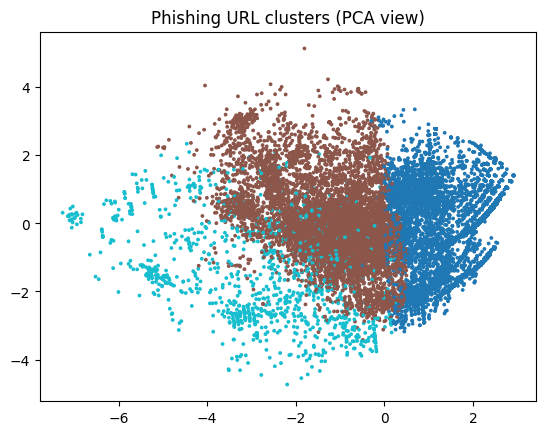

cluster,0,1,2
size,45830,48299,6391
URLLength,27.889,48.102,155.313
DomainLength,18.045,30.376,25.503
IsDomainIP,0.0,0.004,0.072
TLDLength,2.789,2.848,2.813
NoOfSubDomain,0.988,1.342,1.161
CharContinuationRate,0.907,0.569,0.665
HasObfuscation,0.001,0.004,0.04
NoOfObfuscatedChar,0.002,0.026,0.702
ObfuscationRatio,0.0,0.0,0.002


In [24]:
# TASK: Mining Lead - Step 6 (fixed): K-means on phishing URLs (URL-based features only)
phish = df_clean[df_clean[TARGET] == 1].reset_index(drop=True)
Xp = StandardScaler().fit_transform(phish[group_a])
Xp = np.clip(Xp, -3, 3)   # limit extreme values so tiny outlier groups do not take over

# choose k on a 20k sample (faster)
idx = np.random.RandomState(SEED).choice(len(phish), 20000, replace=False)
Xs = Xp[idx]
sub = np.random.RandomState(SEED).choice(len(Xs), 5000, replace=False)  # for silhouette

rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Xs)
    sizes = np.bincount(km.labels_, minlength=k)
    # skip silhouette if the 5000-row subsample misses a cluster
    if len(np.unique(km.labels_[sub])) < 2:
        sil = np.nan
    else:
        sil = silhouette_score(Xs[sub], km.labels_[sub])
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": sil,
                 "smallest_cluster": int(sizes.min())})
k_table = pd.DataFrame(rows)
print(k_table.round(4))
k_table.to_csv("results/kmeans_k_choice.csv", index=False)

if k_table["silhouette"].notna().any():
    BEST_K = int(k_table.loc[k_table["silhouette"].idxmax(), "k"])
else:
    BEST_K = 4   # fallback if every silhouette failed
print("Chosen k:", BEST_K)

final = KMeans(n_clusters=BEST_K, n_init=10, random_state=SEED).fit(Xp)
phish["cluster"] = final.labels_

# profile each cluster (averages in original units)
profile = phish.groupby("cluster")[group_a].mean().round(3)
profile.insert(0, "size", phish["cluster"].value_counts().sort_index())
profile["top_TLDs"] = phish.groupby("cluster")["TLD"].agg(
    lambda s: ", ".join(s.value_counts().head(3).index))
profile["example_urls"] = phish.groupby("cluster")["URL"].agg(
    lambda s: " | ".join(s.head(2)))   # text only, never open these links
profile.to_csv("results/cluster_profiles.csv")

# 2D picture of the clusters
pts = PCA(n_components=2, random_state=SEED).fit_transform(Xs)
plt.scatter(pts[:, 0], pts[:, 1], c=phish["cluster"].values[idx], s=3, cmap="tab10")
plt.title("Phishing URL clusters (PCA view)")
plt.savefig("results/clusters_pca.png", dpi=150, bbox_inches="tight")
plt.show()
profile.T

In [25]:
# TASK: Mining Lead - Step 7: name clusters, save, and zip the results folder
import shutil

names = {0: "Short plain HTTP URLs",
         1: "Medium HTTPS URLs on platform-style subdomains",
         2: "Very long parameter-heavy URLs"}
expected_sizes = {0: 45830, 1: 48299, 2: 6391}

# only apply names if cluster numbers match this run (numbering could change on a rerun)
if profile["size"].to_dict() == expected_sizes:
    profile["cluster_name"] = profile.index.map(names)
    profile.to_csv("results/cluster_profiles.csv")
    print("Names saved.")
else:
    print("Cluster sizes differ from before. Check profile.T and fix the names dict.")

shutil.make_archive("mining_lead_results", "zip", "results")
print(sorted(os.listdir("results")))

Names saved.
['cluster_profiles.csv', 'clusters_pca.png', 'feature_ranking.csv', 'kmeans_k_choice.csv', 'leakage_check.csv', 'model_comparison.csv', 'topk_curve.csv', 'topk_curve.png']
